# Ajuste de SVM y Random Forest con validación por grupos

> **Actualización 26/11/2026.** Este cuaderno se volvió a ejecutar con la base ampliada (332 imágenes, 31 grupos; ver `docs/revision_base_v1.md`). Conserva su protocolo original de tres bloques agrupados como referencia histórica. La evaluación con prueba independiente y las mejoras están en el cuaderno 09.

Continuamos el cuaderno 06 para comprobar si una búsqueda acotada de parámetros mejora la clasificación de calidad externa. Conservamos **las imágenes de la base vigente, las 43 características y los mismos tres bloques externos**, sin modificar etiquetas ni máscaras.

**Hipótesis:** la regularización de SVM y la profundidad/tamaño de hoja de Random Forest pueden ayudar con el desbalance. El problema de las campañas y las pocas calidades intermedias de manzana/limón puede limitar cualquier mejora.

**Regla antes de entrenar:** seleccionar por F1 macro en tres pliegues internos agrupados de cada entrenamiento externo. Las imágenes del bloque externo no participan en esa selección. No ampliaremos la búsqueda según los resultados externos. Esta sigue siendo una evaluación de desarrollo posterior al EDA.

In [1]:
from pathlib import Path
import json
import sys

# Buscar la raíz por archivos versionados, sin exigir datos generados.
candidatos = [Path.cwd(), *Path.cwd().parents]
candidatos += [p / 'proyecto_estado_frutas' for p in candidatos.copy()]
PROYECTO = next((p for p in candidatos if (p / 'config/alcance_actual.json').is_file() and (p / 'src').is_dir()), None)
if PROYECTO is None:
    raise FileNotFoundError('Abrir el cuaderno desde la carpeta del proyecto o notebooks/.')
if str(PROYECTO) not in sys.path:
    sys.path.insert(0, str(PROYECTO))

import pandas as pd
from IPython.display import Image, Markdown, display
from sklearn.model_selection import ParameterGrid
from src.models.modelos_tradicionales import cargar_base
from src.models.ajuste_tradicionales import espacios_busqueda, preparar_plan, cargar_referencia, ejecutar_ajuste

pd.set_option('display.max_colwidth', 110)
pd.set_option('display.precision', 4)
SALIDA = PROYECTO / 'experiments/results/ajuste_modelos'
CHECKPOINTS = PROYECTO / 'experiments/checkpoints/ajuste_modelos'
base, columnas, estado = cargar_base(PROYECTO)
print(f'Base: {len(base)} imágenes, {len(columnas)} características y {base.grupo_particion.nunique()} grupos.')
print('Huella de la base:', estado['sha_base'])

Base: 332 imágenes, 43 características y 31 grupos.
Huella de la base: bf1bbae08894ae929e36ed7926968cd74dbb0a01a50c3fc05c3aa9a2042137c3


## 1. Congelar la comparación y comprobar los pliegues

Se verifica que las predicciones iniciales correspondan a las mismas imágenes, etiquetas y grupos. Cada separación interna se hace solo dentro del entrenamiento externo, conservando juntos los grupos. Todas las etapas de entrenamiento contienen las tres calidades globales. La validación interna puede carecer de alguna clase: se registra y F1 macro sigue usando las tres etiquetas fijas.

In [2]:
externos, internos, asignaciones, cobertura = preparar_plan(base, estado, SALIDA)
referencia = cargar_referencia(base, estado, PROYECTO, asignaciones)
display(pd.crosstab(asignaciones.pliegue_validacion, asignaciones.calidad_revisada))
print('Celdas de calidad ausentes en validación interna:')
display(cobertura.query("etapa == 'validacion' and imagenes == 0"))
print('Particiones externas e internas guardadas para comprobar la separación de grupos.')

calidad_revisada,buena,intermedia,mala
pliegue_validacion,,,
1,105,11,10
2,79,16,11
3,25,67,8


Celdas de calidad ausentes en validación interna:


,exterior,interior,etapa,calidad,imagenes


Particiones externas e internas guardadas para comprobar la separación de grupos.


## 2. Parámetros que se van a probar

- **SVM:** kernel lineal o RBF, `C` de 0,1, 1 y 10, pesos de clase normales o balanceados; para RBF, `gamma='scale'` o 0,01. El escalado permanece dentro del pipeline.
- **Random Forest:** 300 árboles y pesos balanceados, profundidad sin límite o 8, mínimo de 1, 2 o 4 imágenes por hoja y `max_features='sqrt'` o 0,7.

Son **18 candidatos de SVM y 12 de Random Forest**. Ambos espacios incluyen la configuración inicial. Los resultados internos se promedian por pliegue para seleccionar parámetros; las métricas externas se calculan sobre las predicciones OOF reunidas. Son dos usos distintos de las puntuaciones.

In [3]:
for modelo, espacio in espacios_busqueda().items():
    print(modelo, '· candidatos:', len(ParameterGrid(espacio)))
    display(pd.DataFrame(list(ParameterGrid(espacio))).fillna('—'))

SVM · candidatos: 18


,svc__C,svc__class_weight,svc__gamma,svc__kernel
0,0.1,—,scale,rbf
1,0.1,—,0.01,rbf
2,0.1,balanced,scale,rbf
3,0.1,balanced,0.01,rbf
4,1.0,—,scale,rbf
5,1.0,—,0.01,rbf
6,1.0,balanced,scale,rbf
7,1.0,balanced,0.01,rbf
8,10.0,—,scale,rbf
9,10.0,—,0.01,rbf


Random_Forest · candidatos: 12


C:\Users\juanp\AppData\Local\Temp\ipykernel_19728\3476790532.py:3: Pandas4Warning: 'str' is not supported as a fill value for float64 dtype. In a future version, calling fillna with an incompatible value will raise. Explicitly cast to a common dtype before filling.
  display(pd.DataFrame(list(ParameterGrid(espacio))).fillna('—'))


,max_depth,max_features,min_samples_leaf
0,—,sqrt,1
1,—,sqrt,2
2,—,sqrt,4
3,—,0.7,1
4,—,0.7,2
5,—,0.7,4
6,8.0,sqrt,1
7,8.0,sqrt,2
8,8.0,sqrt,4
9,8.0,0.7,1


## 3. Ajustar dentro de cada entrenamiento y evaluar fuera

Para cada bloque externo, seleccionamos parámetros con sus tres separaciones internas, reajustamos el candidato seleccionado sobre todo ese entrenamiento y predecimos el bloque externo. Después hacemos una búsqueda nueva sobre toda la base de desarrollo para guardar los prototipos finales. Las puntuaciones de esa búsqueda final sirven para seleccionar sus parámetros y no se presentan como una prueba independiente.

SVM: ajuste interno del bloque 1/3 (18 candidatos).


  Bloque 1 terminado; F1 externo: 0.380.


SVM: ajuste interno del bloque 2/3 (18 candidatos).


  Bloque 2 terminado; F1 externo: 0.095.


SVM: ajuste interno del bloque 3/3 (18 candidatos).


  Bloque 3 terminado; F1 externo: 0.149.


... (6 outputs left out)

  Bloque 3 terminado; F1 externo: 0.199.


Random_Forest: selección final con los grupos de toda la base de desarrollo.


,exactitud,f1_macro,recall_macro,exactitud_peso_grupo,f1_macro_peso_grupo,recall_macro_peso_grupo
modelo,,,,,,
Referencia_mayoritaria,0.6295,0.2575,0.3333,0.4398,0.2036,0.3333
SVM_inicial,0.3795,0.3180,0.3405,0.3019,0.2945,0.2919
Random_Forest_inicial,0.4247,0.3963,0.4205,0.3726,0.3415,0.3641
SVM_ajustado,0.3614,0.2816,0.2799,0.3296,0.3057,0.2990
Random_Forest_ajustado,0.4066,0.3457,0.3554,0.3118,0.2969,0.3053


,modelo,pliegue,imagenes,exactitud,f1_macro,recall_macro
0,Referencia_mayoritaria,1,126,0.8333,0.3030,0.3333
1,Referencia_mayoritaria,2,106,0.7453,0.2847,0.3333
2,Referencia_mayoritaria,3,100,0.2500,0.1333,0.3333
3,SVM_inicial,1,126,0.6190,0.3009,0.3381
4,SVM_inicial,2,106,0.1321,0.1613,0.2370
5,SVM_inicial,3,100,0.3400,0.2419,0.2309
6,Random_Forest_inicial,1,126,0.8651,0.5226,0.5571
7,Random_Forest_inicial,2,106,0.1604,0.2266,0.3445
8,Random_Forest_inicial,3,100,0.1500,0.2146,0.2548
9,SVM_ajustado,1,126,0.6746,0.3805,0.4206


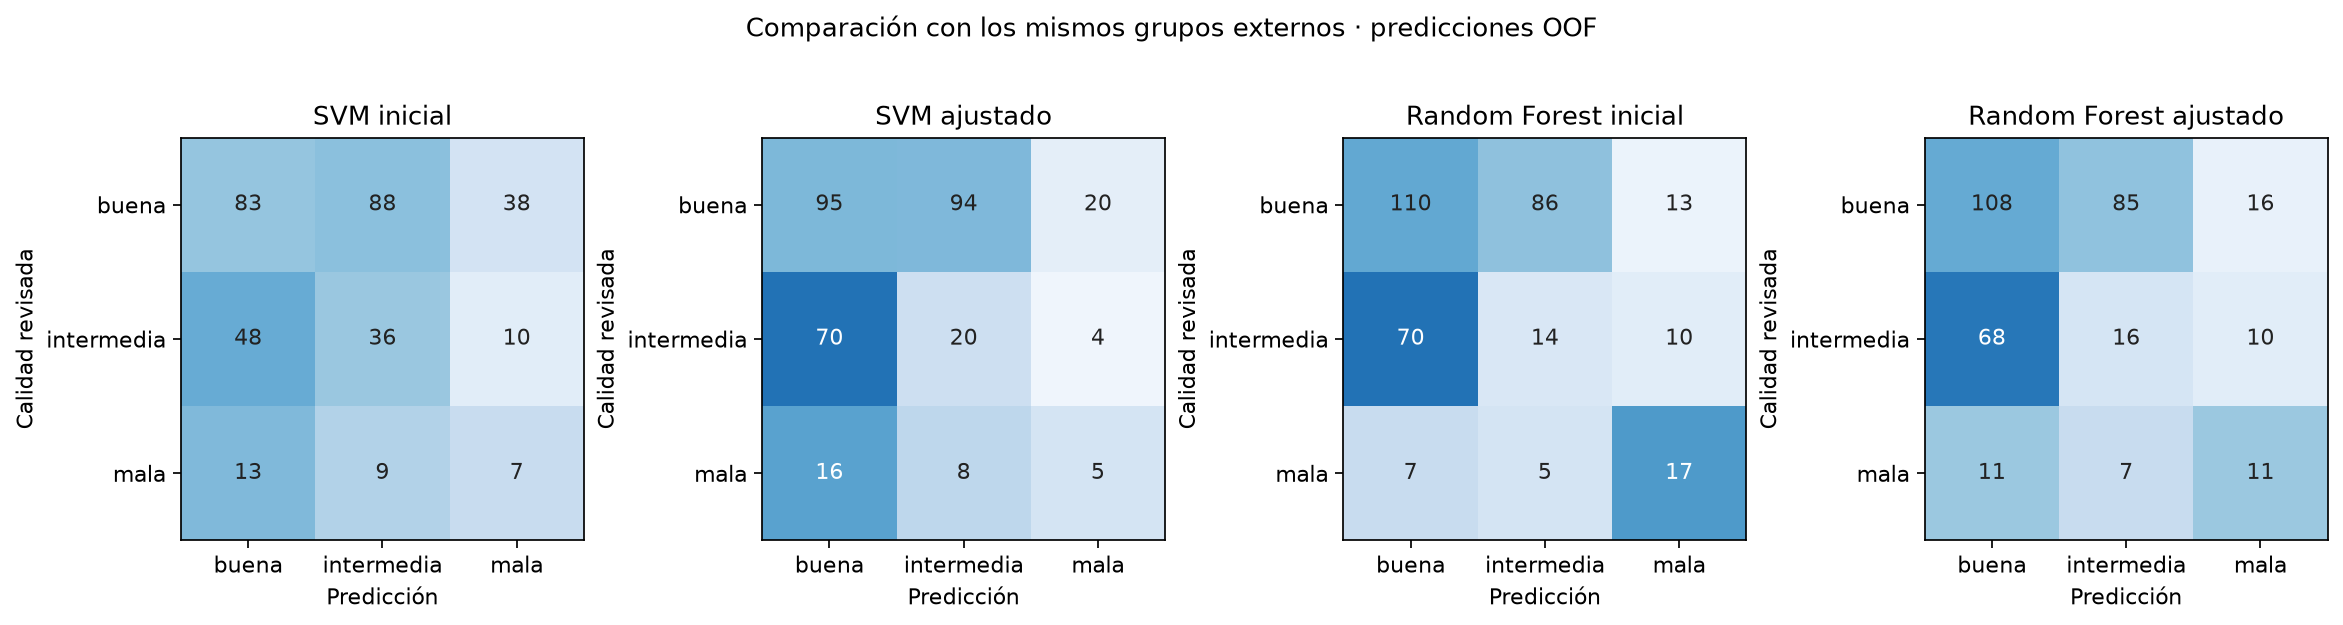

In [4]:
import os
if os.environ.get('FRUTAS_USAR_RESULTADOS') == '1':
    import json
    assert json.loads((SALIDA / 'configuracion_ajuste.json').read_text(encoding='utf-8'))['sha_base'] == estado['sha_base']
    tablas = {f.stem: pd.read_csv(f) for f in SALIDA.glob('*.csv')}
    print('Resultados del entrenamiento completo guardado, verificados contra la base actual.')
else:
    tablas = ejecutar_ajuste(base, columnas, estado, PROYECTO, SALIDA, CHECKPOINTS)
metricas = tablas['metricas_globales'].set_index('modelo')
display(metricas)
display(tablas['metricas_pliegues'])
display(Image(filename=str(SALIDA / '01_comparacion_matrices.png')))

## 4. ¿Mejoran las tres calidades?

Comparar la media global no basta: observamos el recall y el F1 de cada calidad y los errores por fruta. Las columnas con peso por grupo asignan el mismo peso total a cada grupo para explorar la influencia de las campañas grandes. Ninguna de estas métricas elimina las limitaciones de cobertura.

,modelo,calidad,imagenes,recall,f1
0,Referencia_mayoritaria,buena,209,1.0000,0.7726
1,Referencia_mayoritaria,intermedia,94,0.0000,0.0000
2,Referencia_mayoritaria,mala,29,0.0000,0.0000
3,SVM_inicial,buena,209,0.3971,0.4703
4,SVM_inicial,intermedia,94,0.3830,0.3172
5,SVM_inicial,mala,29,0.2414,0.1667
6,Random_Forest_inicial,buena,209,0.5263,0.5556
7,Random_Forest_inicial,intermedia,94,0.1489,0.1407
8,Random_Forest_inicial,mala,29,0.5862,0.4928
9,SVM_ajustado,buena,209,0.4545,0.4872


,modelo,fruta,imagenes,exactitud,f1_macro,recall_macro
0,Referencia_mayoritaria,banano,101,0.0990,0.0601,0.3333
1,Referencia_mayoritaria,limon,95,0.8000,0.2963,0.3333
2,Referencia_mayoritaria,manzana,136,0.9044,0.3166,0.3333
3,SVM_inicial,banano,101,0.3663,0.2541,0.2281
4,SVM_inicial,limon,95,0.0632,0.0437,0.0781
5,SVM_inicial,manzana,136,0.6103,0.3178,0.4495
6,Random_Forest_inicial,banano,101,0.2178,0.2886,0.2996
7,Random_Forest_inicial,limon,95,0.0842,0.1913,0.1988
8,Random_Forest_inicial,manzana,136,0.8162,0.4315,0.5254
9,SVM_ajustado,banano,101,0.2475,0.2729,0.2732


,modelo,grupo_particion,fruta,fuente,imagenes,errores,intermedias,intermedias_correctas
135,Random_Forest_ajustado,7fba1c571586c214,limon,publica,70,70,0,0
141,Random_Forest_ajustado,b3614848dd857cd2,banano,publica,72,64,67,7
147,Random_Forest_ajustado,d4911def2d0d7e29,limon,propia_lote_20261126,9,7,5,0
145,Random_Forest_ajustado,c950dbb6eac0bb4e,banano,propia_lote_20261126,12,6,7,4
144,Random_Forest_ajustado,c7f04911cfdf9ae3,manzana,publica,103,4,0,0
137,Random_Forest_ajustado,91db4003a3e2faba,manzana,propia_lote_20261126,5,4,3,0
126,Random_Forest_ajustado,0c4135a6b30e1c48,limon,propia_lote_20261126,5,4,2,1
138,Random_Forest_ajustado,94d8836cca0dfbac,limon,propia,7,3,2,2


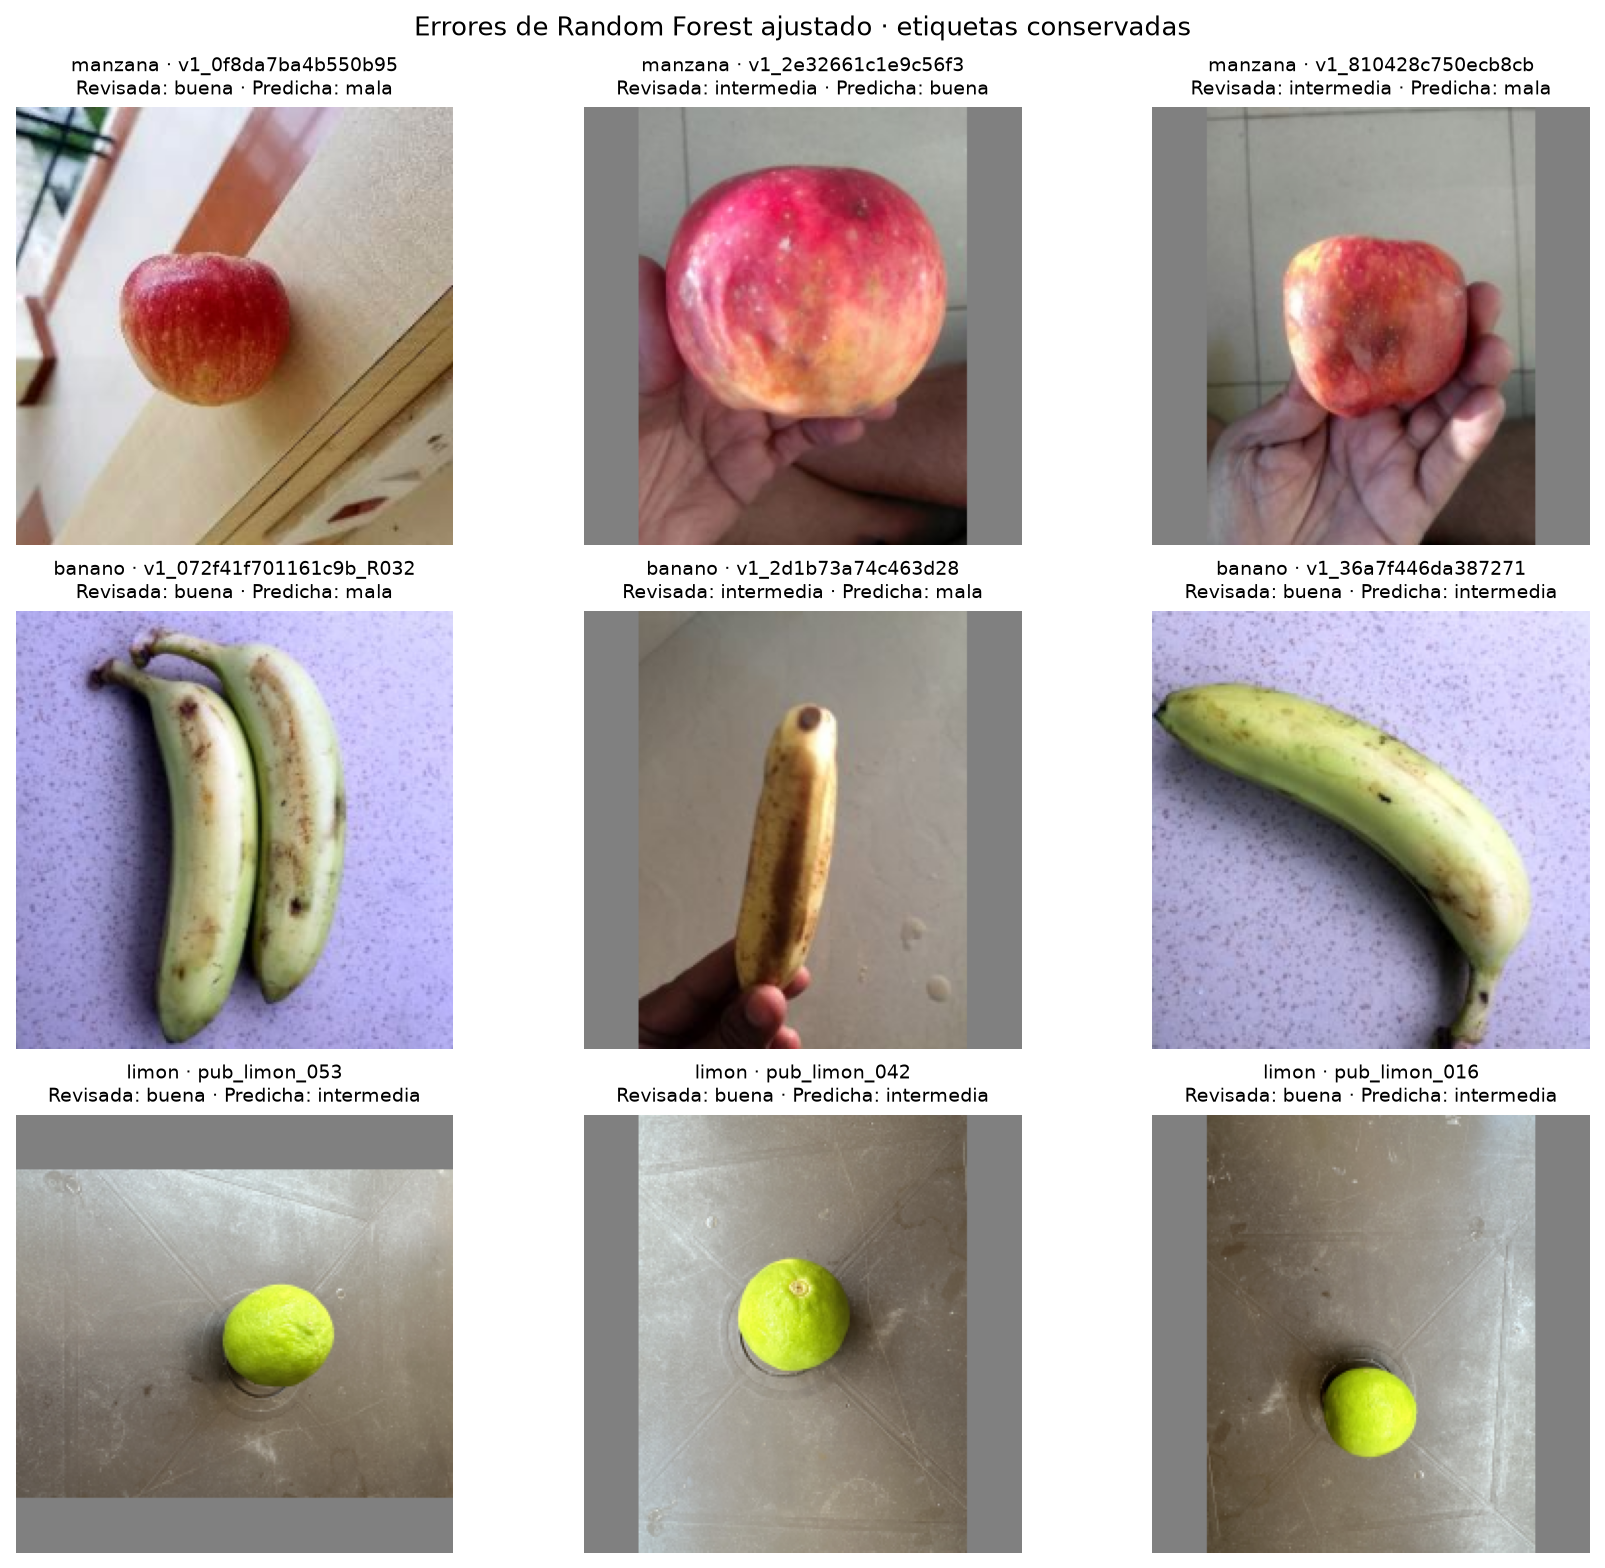

La galería conserva las etiquetas revisadas; una predicción errónea no justifica cambiarlas.


In [5]:
display(tablas['metricas_por_clase'])
display(tablas['metricas_por_fruta'])
grupos = tablas['errores_por_grupo']
display(grupos.query("modelo == 'Random_Forest_ajustado'").sort_values('errores', ascending=False).head(8))
display(Image(filename=str(SALIDA / '02_ejemplos_errores.png')))
print('La galería conserva las etiquetas revisadas; una predicción errónea no justifica cambiarlas.')

## 5. Parámetros seleccionados y modelos guardados

Los parámetros pueden variar entre bloques porque cada selección utiliza datos diferentes. La configuración del prototipo ajustado sobre toda la base puede ser distinta. Conservamos los modelos iniciales del cuaderno 06 y guardamos las versiones ajustadas en otra carpeta; no reemplazamos el primer experimento.

In [6]:
seleccionados = json.loads((SALIDA / 'parametros_seleccionados.json').read_text(encoding='utf-8'))
display(pd.DataFrame(seleccionados))

import joblib
paquete = joblib.load(CHECKPOINTS / 'svm_ajustado.joblib')
assert paquete['sha_base'] == estado['sha_base']
print('Modelo recargado correctamente:', type(paquete['modelo']).__name__)
print('Entradas requeridas:', len(paquete['caracteristicas']), 'características extraídas de la imagen.')
print('Modelos guardados:', [p.name for p in CHECKPOINTS.glob('*.joblib')])

,modelo,etapa,exterior,parametros,f1_interno_seleccion
0,SVM,evaluacion_externa,1,"{'svc__C': 0.1, 'svc__class_weight': None, 'svc__kernel': 'linear'}",0.3958
1,SVM,evaluacion_externa,2,"{'svc__C': 1.0, 'svc__class_weight': None, 'svc__gamma': 0.01, 'svc__kernel': 'rbf'}",0.5362
2,SVM,evaluacion_externa,3,"{'svc__C': 1.0, 'svc__class_weight': None, 'svc__kernel': 'linear'}",0.2517
3,SVM,prototipo_final,0,"{'svc__C': 10.0, 'svc__class_weight': 'balanced', 'svc__kernel': 'linear'}",0.3362
4,Random_Forest,evaluacion_externa,1,"{'max_depth': None, 'max_features': 0.7, 'min_samples_leaf': 2}",0.4920
5,Random_Forest,evaluacion_externa,2,"{'max_depth': None, 'max_features': 'sqrt', 'min_samples_leaf': 1}",0.5894
6,Random_Forest,evaluacion_externa,3,"{'max_depth': None, 'max_features': 'sqrt', 'min_samples_leaf': 4}",0.2429
7,Random_Forest,prototipo_final,0,"{'max_depth': None, 'max_features': 0.7, 'min_samples_leaf': 4}",0.3281


Modelo recargado correctamente: Pipeline
Entradas requeridas: 43 características extraídas de la imagen.
Modelos guardados: ['random_forest_ajustado.joblib', 'svm_ajustado.joblib']


## 6. Decisión del experimento

La comparación siguiente informa lo observado sin volver a elegir parámetros con los bloques externos. Como el diseño se decidió después de conocer el EDA y el resultado inicial, este cuaderno sigue siendo parte del desarrollo. Una mejora local no asegura el mismo comportamiento en capturas independientes.

**Registro histórico (base de 291 imágenes, 25/11/2026):** Random Forest inicial obtuvo F1 macro 0,429; SVM ajustado, 0,373; Random Forest ajustado, 0,388. Las cifras de la base vigente se calculan en la celda siguiente y pueden diferir. La decisión final de modelo se toma en el cuaderno 09 con una prueba independiente.

In [7]:
for modelo in ['SVM', 'Random_Forest']:
    inicial = metricas.loc[f'{modelo}_inicial', 'f1_macro']
    ajustado = metricas.loc[f'{modelo}_ajustado', 'f1_macro']
    display(Markdown(f"**{modelo.replace('_', ' ')}:** F1 macro {inicial:.3f} → {ajustado:.3f}; cambio {ajustado-inicial:+.3f}."))

recall_intermedio = tablas['metricas_por_clase'].query("calidad == 'intermedia'")[['modelo', 'recall']]
display(recall_intermedio)
display(Markdown(
    '**Continuación:** conservar los resultados iniciales y ajustados, revisar los errores por campaña y '
    'priorizar nuevas capturas de manzanas y limones intermedios, frutos malos y bananos buenos. '
    'La cobertura de esas combinaciones debe mejorar antes de interpretar un modelo como definitivo. '
    'El trabajo ya puede continuar con la integración de inferencia y el modelo de aprendizaje profundo, '
    'usando estos resultados como referencia y las mismas reglas de separación.'
))

**SVM:** F1 macro 0.318 → 0.282; cambio -0.036.

**Random Forest:** F1 macro 0.396 → 0.346; cambio -0.051.

,modelo,recall
1,Referencia_mayoritaria,0.0000
4,SVM_inicial,0.3830
7,Random_Forest_inicial,0.1489
10,SVM_ajustado,0.2128
13,Random_Forest_ajustado,0.1702


**Continuación:** conservar los resultados iniciales y ajustados, revisar los errores por campaña y priorizar nuevas capturas de manzanas y limones intermedios, frutos malos y bananos buenos. La cobertura de esas combinaciones debe mejorar antes de interpretar un modelo como definitivo. El trabajo ya puede continuar con la integración de inferencia y el modelo de aprendizaje profundo, usando estos resultados como referencia y las mismas reglas de separación.